scope.glitch.width  2800
scope.glitch.mmcm_locked  True
exception Read Memory NACK


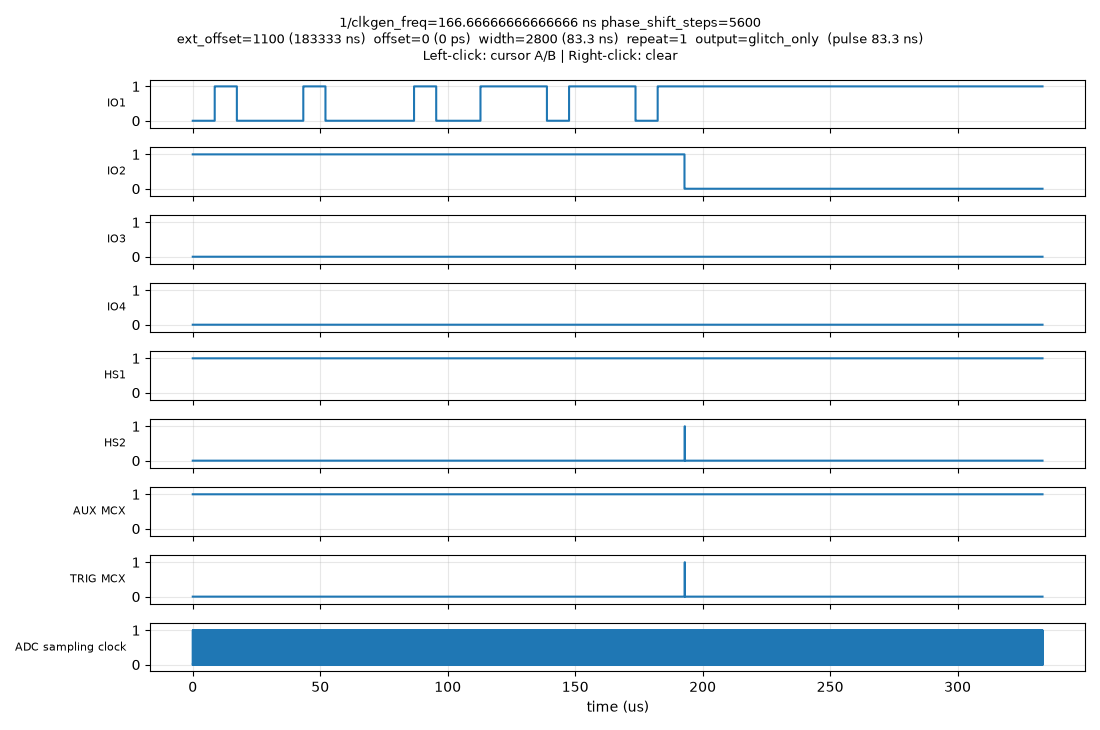

HS2: sample period 8.333 ns
  pulses: 1  mean: 83.33 ns  min: 83.33 ns  max: 83.33 ns
    start 192963.65 ns  on-time 83.33 ns
scope.glitch.width  2800
scope.glitch.mmcm_locked  True
exception Read Memory NACK


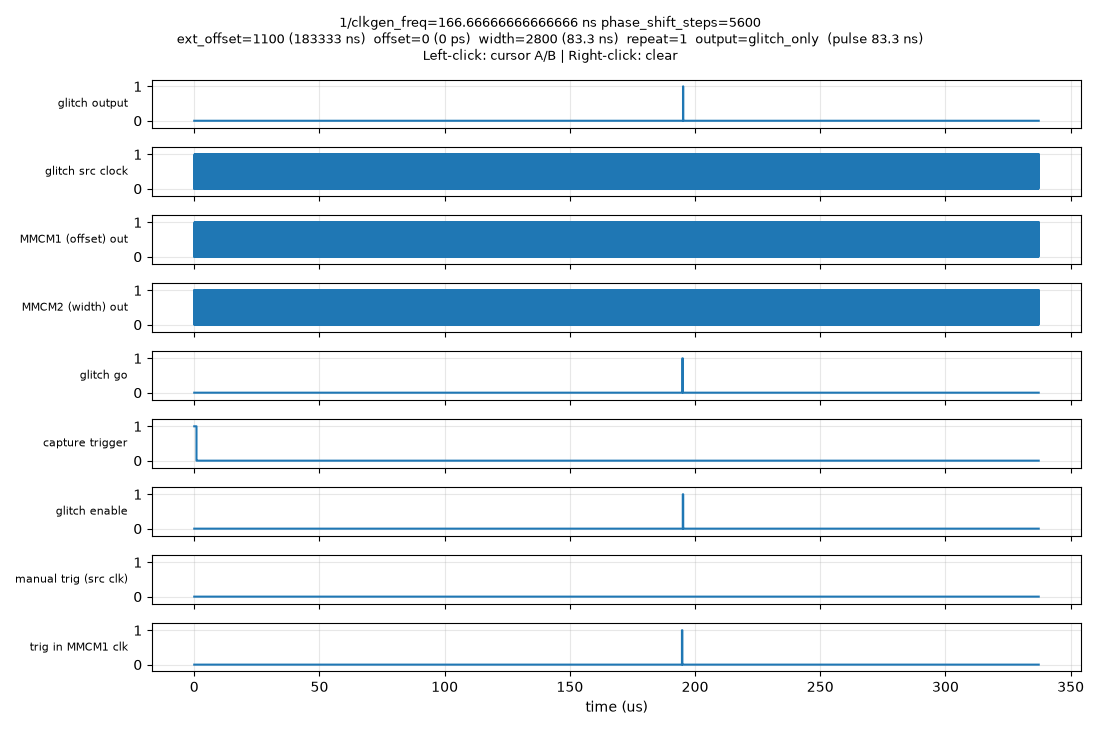

In [1]:
%matplotlib widget
%run ./LibStm32Boot.ipynb
%run ./LibLoadSaveSettings.ipynb
%run ./LibLogicAnalyserGlitchTools.ipynb

import numpy as np
import matplotlib.pyplot as plt


FLASH_SIZE = 256      # test
CHUNK = 64                   # SAM3U RX buffer holds only 128-200 bytes
BAUD = 115200
BYTE_GAP = 0.0001              # back-to-back bytes get NACKed by the bootloader
RETRIES = 3
debug=False

out_path = "flash_dump.bin"
size = FLASH_SIZE

try:
    scope.dis()
except:
    pass
try:
    fig1.dis()
except:
    pass
try:
    fig2.dis()
except:
    pass

def init_logic_analyser(scope, glitch=True, capture_group='CW 20-pin'):
    scope.errors.clear()
    scope.adc.segments = 1
    scope.gain.db = 25

    scope.io.hs2 = 'glitch'              # Glitch on HS2, for example to feed an external device
    scope.io.glitch_trig_mcx = 'glitch' # Glitch pulse on the Trigger/Glitch Out MCX connector
    scope.io.tio1 = "serial_tx"
    scope.io.tio2 = "serial_rx"
    scope.io.tio3 = "gpio_high"

    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"
    scope.glitch.trigger_src = "ext_single"   # glitch also fires on that trigger

    scope.adc.basic_mode = "falling_edge"   # catch the actual start bit
    scope.adc.presamples = 0
    scope.adc.samples = 10
    scope.adc.lo_gain_errors_disabled = True
    
    # --- Logic analyzer: record trigger + glitch signals ---
    scope.LA.enabled = True
    scope.LA.capture_group = capture_group
    scope.LA.capture_depth = 40000
    scope.LA.trigger_source = 'capture'     
    scope.LA.oversampling_factor = 20
    scope.LA.downsample = 1   # try 100 to 1000 until you see the whole exchange

    if glitch:
        scope.glitch.enabled = True
        scope.io.glitch_hp = True
        scope.io.glitch_lp = True
    else:
        scope.glitch.enabled = False
        scope.io.glitch_hp = False
        scope.io.glitch_lp = False

    scope.glitch.clk_src = 'pll'
    #scope.glitch.output = "enable_only"  # one large glitch repeat times
    scope.glitch.output = "glitch_only" # multiple short (width) glitches
    


scope = cw.scope()
scope.default_setup(verbose=False)
target = cw.target(scope, cw.targets.SimpleSerial)
set_debug_pin(True)

scope.clock.clkgen_freq = 6e6
ser = target.ser
ser.setBaud(BAUD)
ser.setParity("even")

init_logic_analyser(scope)


enter_bootloader()

# Get ID as a sanity check (expect 0462 for the L45x family)
get_product_id()

def trigger_operation():
    data = []
    try:
        data = read_mem(addr=FLASH_BASE, length=256)
    except Exception as e:
        print(f"exception {e}")
    return data

def pre_arm_action(scope):
    pass

def post_arm_trigger_action(scope):
    trigger_operation()

def post_capture_action(scope):
    pass


def capture_with_la(scope, capture_group, addr=FLASH_BASE, length=256, ext_offset=10, offset=0, width=3000, repeat=1, trigger='trigger_glitch'):
    scope.errors.clear()

    scope.glitch.offset = offset
    scope.glitch.ext_offset = ext_offset
    scope.glitch.width = width
    scope.glitch.repeat = repeat

    print("scope.glitch.width ", scope.glitch.width)

    scope.LA.capture_group = capture_group
    ser.flush()
    time.sleep(0.01)
    scope.LA.enabled = True
    scope.LA.arm()   
    scope.arm()
    print("scope.glitch.mmcm_locked ", scope.glitch.mmcm_locked)
    time.sleep(0.003)
    data = trigger_operation()
    
    res = read_capture_data(scope)

    scope.LA.enabled = False
    return res, data





off=0
addr = FLASH_BASE + off
length = min(CHUNK, size - off)

# 8e6  1350 - 1500
# 6e6  1000 - 1100  2800 reset  2700 ok
ext_offset = 1100
width = 2800
offset = 0
repeat = 1

res, data = capture_with_la(scope, 'CW 20-pin', addr, length, ext_offset=ext_offset, width=width, offset=offset, repeat=repeat)
save_scope_settings(scope, "first_capture.json")

f_la = scope.LA.sampling_clock_frequency / scope.LA.downsample
fig1 = plot_la_interactive(res, title=caption(calc_glitch_times(scope)))
mesured_pulse = measure_on_time(res, "HS2")

res, data = capture_with_la(scope, 'glitch', ext_offset=ext_offset, width=width, offset=offset, repeat=repeat)
save_scope_settings(scope, "second_capture.json")

fig2 = plot_la_interactive(res, title=caption(calc_glitch_times(scope)))


scope.dis()
scope = None
